# Projet F8 : Battre la marche aléatoire

**Nom :** AYA EL ADRAOUI · **Code Apogée :** 22010161 · **Groupe :** S7 G2 Finance  


In [1]:
# Importation des bibliothèques
!pip install -q yfinance
import os
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

# Dossiers du projet, graine et style
os.makedirs("data/raw", exist_ok=True)
os.makedirs("figures", exist_ok=True)
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [2]:
# Téléchargement (ou relecture si le fichier existe déjà)
tickers = ["BAC", "C", "GS", "JPM", "MS", "WFC"]
fichier = "data/raw/banques_2006_2015.csv"

if os.path.exists(fichier):
    brut = pd.read_csv(fichier, header=[0, 1], index_col=0, parse_dates=True)
else:
    brut = yf.download(tickers, start="2006-01-01", end="2016-01-01", auto_adjust=True, progress=False)
    brut.to_csv(fichier)
    print("Date d'extraction :", datetime.date.today())

print("Dimensions :", brut.shape)
prix = brut["Close"]
jpm = pd.DataFrame({"prix": brut["Close"]["JPM"], "volume": brut["Volume"]["JPM"]})
print("Période :", jpm.index.min().date(), "→", jpm.index.max().date(), "|", len(jpm), "séances")
print("Valeurs manquantes :", int(jpm.isna().sum().sum()), "| Doublons de dates :", int(jpm.index.duplicated().sum()))
jpm.head()

Date d'extraction : 2026-11-24
Dimensions : (2517, 30)
Période : 2006-01-03 → 2015-12-31 | 2517 séances
Valeurs manquantes : 0 | Doublons de dates : 0


,prix,volume
Date,,
2006-01-03,23.410891,12838600
2006-01-04,23.275778,13491500
2006-01-05,23.346277,8109400
2006-01-06,23.510759,7966900
2006-01-09,23.892622,16575200


### Dictionnaire des variables

| Nom | Rôle | Type | Unité | Manquants |
|---|---|---|---|---|
| `prix` | base de calcul | numérique | dollars (USD) | 0 |
| `rendement` | variable de base | numérique | % par jour | 1er jour (retiré) |
| `rend_lag1` à `rend_lag5` | entrées | numérique | % | 5 premiers jours (retirés) |
| `volatilite_20j` | entrée | numérique | % (écart-type sur 20 jours) | 20 premiers jours (retirés) |
| `momentum_20j` | entrée | numérique | % (variation sur 20 jours) | 20 premiers jours (retirés) |
| `ecart_mm50` | entrée | numérique | % (écart à la moyenne mobile 50 jours) | 50 premiers jours (retirés) |
| `var_volume` | entrée | numérique | log (volume / moyenne 20 jours) | 20 premiers jours (retirés) |
| `hausse_demain` | **cible** | binaire | 1 = hausse, 0 = baisse | dernier jour (retiré) |

**Pas de fuite de données :** toutes les variables d'entrée sont calculées avec des informations **connues le jour même**. Seule la cible regarde le lendemain.

## C. Exploration et préparation

In [3]:
# Construction des variables (uniquement avec le passé)
jpm["rendement"] = jpm["prix"].pct_change() * 100
for k in range(1, 6):
    jpm[f"rend_lag{k}"] = jpm["rendement"].shift(k - 1)
jpm["volatilite_20j"] = jpm["rendement"].rolling(20).std()
jpm["momentum_20j"] = jpm["prix"].pct_change(20) * 100
jpm["ecart_mm50"] = (jpm["prix"] / jpm["prix"].rolling(50).mean() - 1) * 100
jpm["var_volume"] = np.log(jpm["volume"] / jpm["volume"].rolling(20).mean())

# Cible : le rendement de DEMAIN est-il positif ?
jpm["hausse_demain"] = (jpm["rendement"].shift(-1) > 0).astype(int)

# On retire le dernier jour (pas de lendemain) et les premiers jours incomplets
jpm = jpm.iloc[:-1].dropna()
variables = [f"rend_lag{k}" for k in range(1, 6)] + ["volatilite_20j", "momentum_20j", "ecart_mm50", "var_volume"]

print("Séances utilisables :", len(jpm))
print("Part des jours de hausse :", round(jpm["hausse_demain"].mean(), 3))
print("Jours avec |rendement| > 10 % :", int((jpm["rendement"].abs() > 10).sum()))
jpm[["rendement"] + variables].describe().round(2)

Séances utilisables : 2467
Part des jours de hausse : 0.505
Jours avec |rendement| > 10 % : 35


,rendement,rend_lag1,rend_lag2,rend_lag3,rend_lag4,rend_lag5,volatilite_20j,momentum_20j,ecart_mm50,var_volume
count,2467.00,2467.00,2467.00,2467.00,2467.00,2467.00,2467.00,2467.00,2467.00,2467.00
mean,0.07,0.07,0.07,0.07,0.07,0.07,2.16,0.99,0.86,-0.05
std,2.79,2.79,2.79,2.79,2.79,2.79,1.82,9.11,7.69,0.33
min,-20.73,-20.73,-20.73,-20.73,-20.73,-20.73,0.56,-42.45,-41.41,-1.56
25%,-0.99,-0.99,-0.99,-0.99,-0.99,-1.00,1.13,-3.75,-2.96,-0.26
50%,0.02,0.02,0.02,0.02,0.02,0.02,1.52,1.42,1.56,-0.07
75%,1.04,1.04,1.04,1.04,1.04,1.04,2.36,5.65,5.03,0.14
max,25.10,25.10,25.10,25.10,25.10,25.10,10.60,84.13,38.49,1.77


**Décisions de nettoyage :**

- **Valeurs manquantes :** seuls les premiers jours (pas assez d'historique pour les moyennes mobiles) et le dernier jour (pas de lendemain) sont incomplets. On les retire, ce qui représente très peu de lignes.
- **Doublons :** on vérifie qu'aucune date n'apparaît deux fois.
- **Valeurs extrêmes :** les rendements supérieurs à 10 % en valeur absolue correspondent à de **vrais événements de la crise de 2008**. On les **garde**, car les supprimer cacherait la réalité du risque.
- **Équilibre des classes :** environ la moitié des jours sont des hausses, donc l'exactitude est un indicateur adapté.

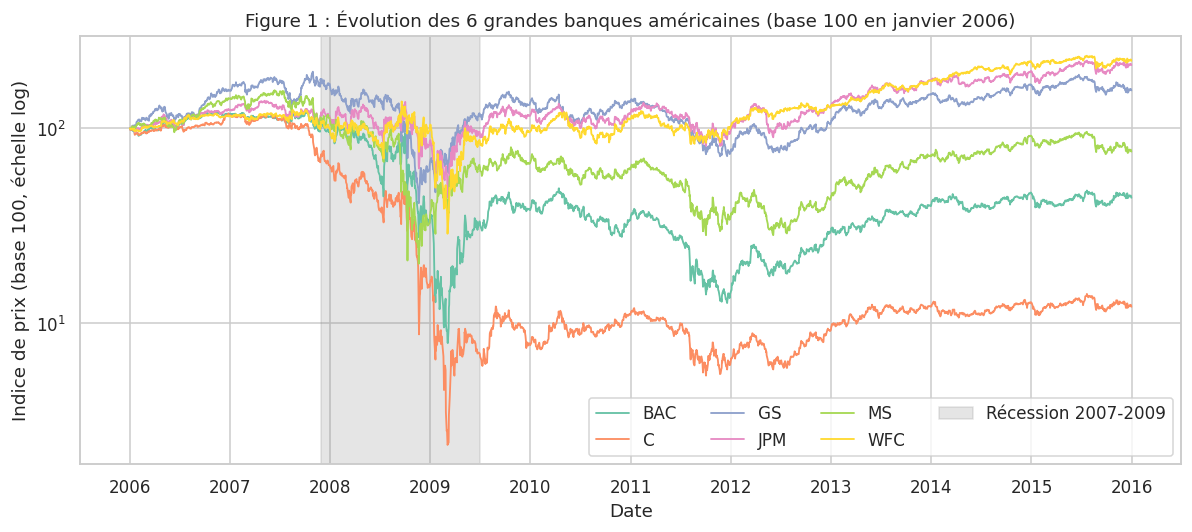

In [4]:
# Figure 1 : évolution des 6 banques
fig, ax = plt.subplots(figsize=(11, 5))
for t in tickers:
    ax.plot(prix.index, prix[t] / prix[t].iloc[0] * 100, label=t, linewidth=1.2)
ax.axvspan(pd.Timestamp("2007-12-01"), pd.Timestamp("2009-06-30"), color="grey", alpha=0.2, label="Récession 2007-2009")
ax.set_yscale("log")
ax.set_title("Figure 1 : Évolution des 6 grandes banques américaines (base 100 en janvier 2006)")
ax.set_xlabel("Date")
ax.set_ylabel("Indice de prix (base 100, échelle log)")
ax.legend(ncol=4)
plt.tight_layout()
plt.savefig("figures/fig1_prix_banques.png")
plt.show()

**Interprétation :** les six banques s'effondrent pendant la crise de 2007-2009 (zone grise). Citigroup et Bank of America sont les plus touchées et ne retrouvent jamais leur niveau de 2006. JPMorgan résiste mieux et remonte ensuite. Toutes les banques évoluent ensemble, ce qui montre un fort **risque systémique** dans le secteur.

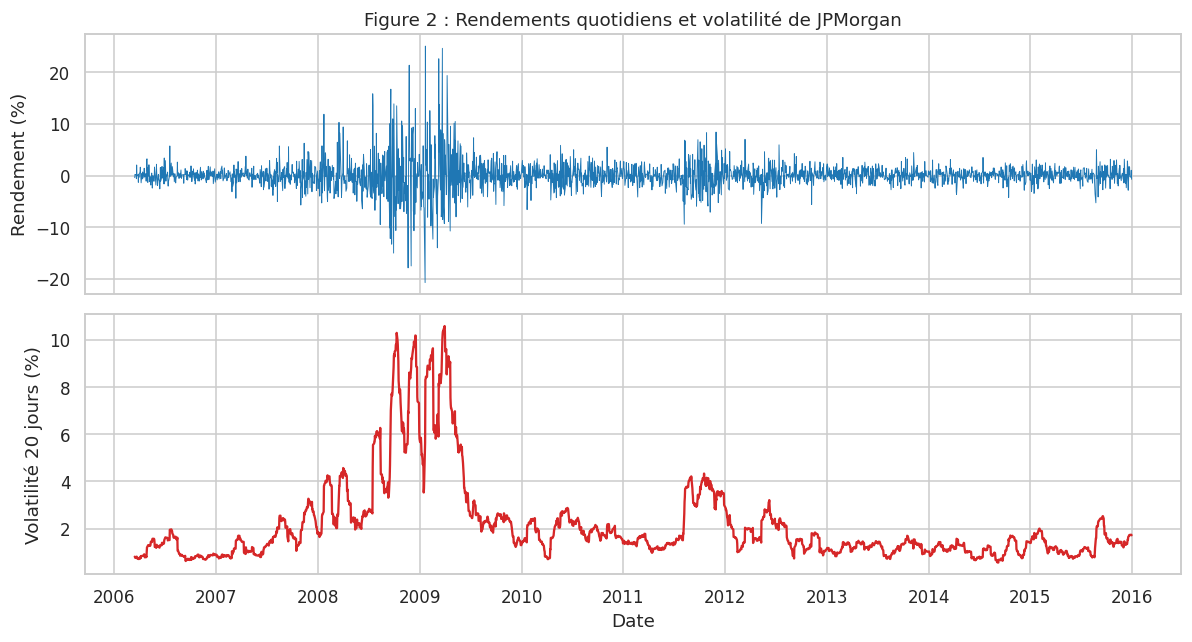

In [5]:
# Figure 2 : rendements quotidiens et volatilité de JPMorgan
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(jpm.index, jpm["rendement"], color="tab:blue", linewidth=0.6)
axes[0].set_title("Figure 2 : Rendements quotidiens et volatilité de JPMorgan")
axes[0].set_ylabel("Rendement (%)")
axes[1].plot(jpm.index, jpm["volatilite_20j"], color="tab:red")
axes[1].set_ylabel("Volatilité 20 jours (%)")
axes[1].set_xlabel("Date")
plt.tight_layout()
plt.savefig("figures/fig2_rendements_volatilite.png")
plt.show()

**Interprétation :** les rendements tournent autour de zéro, mais leur amplitude change beaucoup. La volatilité explose fin 2008 puis redescend. Les jours agités se suivent : c'est le **regroupement de la volatilité**. On peut donc prévoir en partie le **niveau de risque**, ce qui ne veut pas dire qu'on peut prévoir la **direction** du cours.

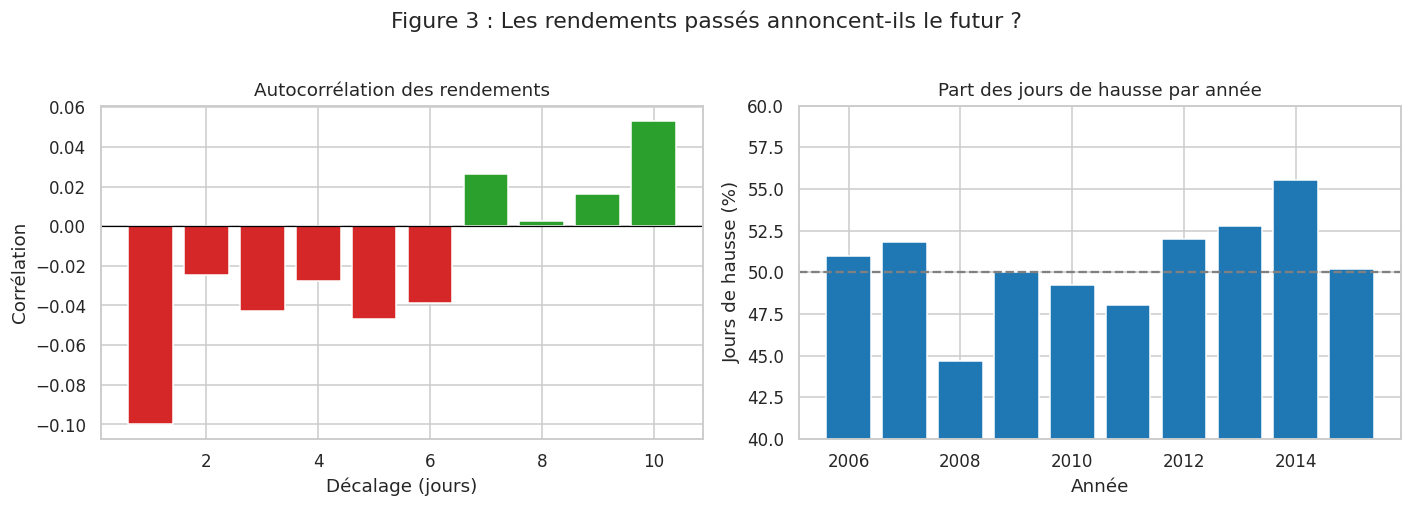

Autocorrélation au décalage 1 : -0.1


In [6]:
# Figure 3 : autocorrélation et part des jours de hausse
autocorr = [jpm["rendement"].autocorr(lag=k) for k in range(1, 11)]
hausse_annee = jpm.groupby(jpm.index.year)["hausse_demain"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, 11), autocorr, color=["tab:red" if a < 0 else "tab:green" for a in autocorr])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Autocorrélation des rendements")
axes[0].set_xlabel("Décalage (jours)")
axes[0].set_ylabel("Corrélation")
axes[1].bar(hausse_annee.index, hausse_annee.values, color="tab:blue")
axes[1].axhline(50, color="grey", linestyle="--")
axes[1].set_title("Part des jours de hausse par année")
axes[1].set_xlabel("Année")
axes[1].set_ylabel("Jours de hausse (%)")
axes[1].set_ylim(40, 60)
plt.suptitle("Figure 3 : Les rendements passés annoncent-ils le futur ?", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig3_autocorrelation.png")
plt.show()
print("Autocorrélation au décalage 1 :", round(autocorr[0], 3))

**Interprétation :** les autocorrélations sont **très proches de zéro**. Le rendement d'aujourd'hui ne dit presque rien sur celui de demain, ce qui est cohérent avec la marche aléatoire. La part des jours de hausse reste proche de 50 % chaque année. Il faut donc s'attendre à ce qu'un modèle ait **beaucoup de mal** à faire mieux que le hasard.

### Découpage chronologique

Comme ce sont des séries temporelles, on **ne mélange pas les dates** : on apprend sur le passé et on teste sur le futur.

- **Entraînement :** 2006 à 2013
- **Test :** 2014 à 2015, utilisé une seule fois à la fin

Les hyperparamètres sont réglés par **validation croisée chronologique** (`TimeSeriesSplit`, 5 plis), uniquement sur l'entraînement. La standardisation est placée dans un `Pipeline`, donc elle est apprise sur l'entraînement seulement.

In [7]:
# Découpage chronologique
train = jpm.loc[:"2013-12-31"]
test = jpm.loc["2014-01-01":]
X_train, y_train = train[variables], train["hausse_demain"]
X_test, y_test = test[variables], test["hausse_demain"]

print("Entraînement :", X_train.index.min().date(), "→", X_train.index.max().date(), "|", len(X_train), "séances")
print("Test :", X_test.index.min().date(), "→", X_test.index.max().date(), "|", len(X_test), "séances")
print("Part de hausses (entraînement / test) :", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Entraînement : 2006-03-15 → 2013-12-31 | 1964 séances
Test : 2014-01-02 → 2015-12-30 | 503 séances
Part de hausses (entraînement / test) : 0.499 / 0.529


## D. Algorithme retenu : la régression logistique

**Principe :** la régression logistique calcule un score à partir des variables, puis le transforme en **probabilité de hausse**, comprise entre 0 et 1. Si la probabilité dépasse 0,5, on prédit une hausse. C'est l'algorithme de classification binaire le plus simple et le plus **interprétable** : chaque coefficient indique si une variable pousse vers la hausse ou vers la baisse. Il convient bien ici, car on cherche à savoir **si** une information passée a un effet, pas à construire une boîte noire.

**Équation :**

$$P(y_{t+1} = 1 \mid x_t) = \sigma(z) = \frac{1}{1 + e^{-z}} \quad \text{avec} \quad z = \beta_0 + \sum_{j=1}^{9} \beta_j \, x_{j,t}$$

- $y_{t+1}$ : direction du lendemain (1 = hausse, 0 = baisse)
- $x_{j,t}$ : valeur de la variable $j$ le jour $t$ (standardisée)
- $\beta_0$ : constante ; $\beta_j$ : coefficient de la variable $j$. Ce sont les **paramètres appris**.
- $\sigma$ : fonction sigmoïde, qui transforme $z$ en probabilité

Les coefficients sont appris en minimisant la **perte logistique** plus une pénalité $\frac{1}{C}\sum \beta_j^2$, qui empêche les coefficients de devenir trop grands.

**Deux hyperparamètres réglés :**

1. **C** (force de régularisation) : un petit C donne des coefficients plus faibles et un modèle plus prudent, un grand C laisse le modèle coller davantage aux données.
2. **class_weight** : `None` ou `"balanced"`. `"balanced"` rééquilibre le poids des hausses et des baisses.

**Alternative comparée :** la **forêt aléatoire**, plus flexible car elle capte des effets non linéaires, mais plus difficile à interpréter et plus exposée au surapprentissage.

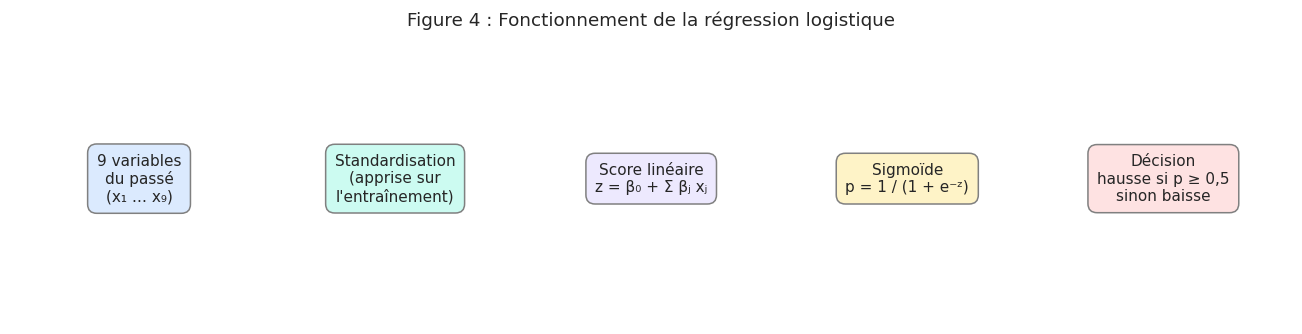

In [8]:
# Figure 4 : schéma de la régression logistique
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.axis("off")
etapes = ["9 variables\ndu passé\n(x₁ … x₉)", "Standardisation\n(apprise sur\nl'entraînement)",
          "Score linéaire\nz = β₀ + Σ βⱼ xⱼ", "Sigmoïde\np = 1 / (1 + e⁻ᶻ)", "Décision\nhausse si p ≥ 0,5\nsinon baisse"]
couleurs = ["#dbeafe", "#ccfbf1", "#ede9fe", "#fef3c7", "#fee2e2"]
for i, (txt, c) in enumerate(zip(etapes, couleurs)):
    ax.text(0.1 + i * 0.2, 0.5, txt, ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.6", facecolor=c, edgecolor="grey"))
    if i < 4:
        ax.annotate("", xy=(0.185 + i * 0.2, 0.5), xytext=(0.155 + i * 0.2, 0.5),
                    arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_title("Figure 4 : Fonctionnement de la régression logistique", fontsize=12)
plt.tight_layout()
plt.savefig("figures/fig4_schema_logistique.png")
plt.show()

## E. Expérimentation et comparaison

**Deux références naïves :**

1. **Classe majoritaire :** prédire toujours la direction la plus fréquente dans l'entraînement.
2. **Persistance :** prédire que demain ira dans le même sens qu'aujourd'hui.

On règle ensuite les hyperparamètres de la régression logistique et de la forêt aléatoire par validation croisée chronologique.

In [9]:
# Réglage des hyperparamètres (sur l'entraînement uniquement)
validation = TimeSeriesSplit(n_splits=5)

logit = Pipeline([("echelle", StandardScaler()), ("modele", LogisticRegression(max_iter=1000))])
grille_logit = GridSearchCV(logit,
                            {"modele__C": [0.001, 0.01, 0.1, 1, 10],
                             "modele__class_weight": [None, "balanced"]},
                            cv=validation, scoring="accuracy")
grille_logit.fit(X_train, y_train)
print("Meilleurs hyperparamètres :", grille_logit.best_params_)
print("Exactitude en validation :", round(grille_logit.best_score_, 3))

foret = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
grille_foret = GridSearchCV(foret, {"max_depth": [2, 3, 5]}, cv=validation, scoring="accuracy")
grille_foret.fit(X_train, y_train)
print("\nForêt, meilleure profondeur :", grille_foret.best_params_)
print("Forêt, exactitude en validation :", round(grille_foret.best_score_, 3))

Meilleurs hyperparamètres : {'modele__C': 0.001, 'modele__class_weight': 'balanced'}
Exactitude en validation : 0.533

Forêt, meilleure profondeur : {'max_depth': 3}
Forêt, exactitude en validation : 0.537


In [10]:
# Tableau modèle / références sur le jeu de test (utilisé une seule fois)
majoritaire = int(y_train.mean() >= 0.5)
pred_ref = np.full(len(y_test), majoritaire)
pred_persist = (X_test["rend_lag1"] > 0).astype(int)

modele_final = grille_logit.best_estimator_
proba_logit = modele_final.predict_proba(X_test)[:, 1]
pred_logit = modele_final.predict(X_test)
proba_foret = grille_foret.best_estimator_.predict_proba(X_test)[:, 1]
pred_foret = grille_foret.best_estimator_.predict(X_test)

tableau = pd.DataFrame({
    "Modèle": ["Référence : classe majoritaire", "Référence : persistance",
               "Régression logistique (principal)", "Forêt aléatoire (alternative)"],
    "Exactitude entraînement": [
        accuracy_score(y_train, np.full(len(y_train), majoritaire)),
        accuracy_score(y_train, (X_train["rend_lag1"] > 0).astype(int)),
        accuracy_score(y_train, modele_final.predict(X_train)),
        accuracy_score(y_train, grille_foret.best_estimator_.predict(X_train))],
    "Exactitude test": [
        accuracy_score(y_test, pred_ref), accuracy_score(y_test, pred_persist),
        accuracy_score(y_test, pred_logit), accuracy_score(y_test, pred_foret)],
    "AUC test": [0.5, roc_auc_score(y_test, X_test["rend_lag1"]),
                 roc_auc_score(y_test, proba_logit), roc_auc_score(y_test, proba_foret)],
})
tableau.round(3)

,Modèle,Exactitude entraînement,Exactitude test,AUC test
0,Référence : classe majoritaire,0.501,0.471,0.500
1,Référence : persistance,0.452,0.485,0.462
2,Régression logistique (principal),0.542,0.555,0.530
3,Forêt aléatoire (alternative),0.609,0.513,0.527


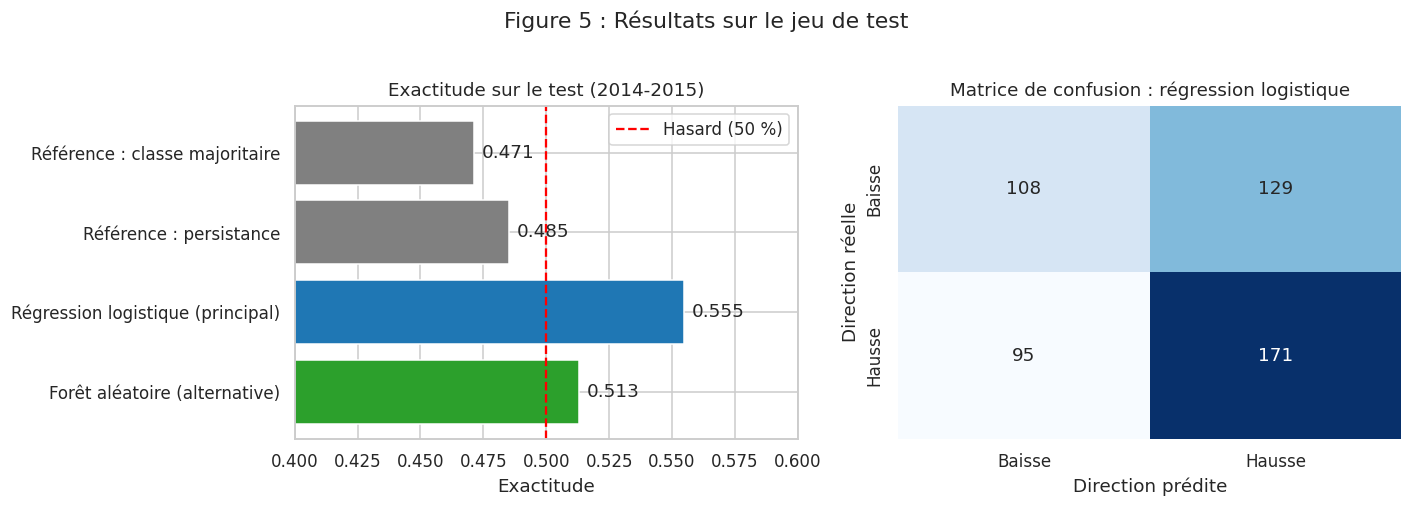

In [11]:
# Figure 5 : résultats sur le test
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(tableau["Modèle"], tableau["Exactitude test"], color=["grey", "grey", "tab:blue", "tab:green"])
axes[0].axvline(0.5, color="red", linestyle="--", label="Hasard (50 %)")
for i, v in enumerate(tableau["Exactitude test"]):
    axes[0].text(v + 0.003, i, f"{v:.3f}", va="center")
axes[0].set_xlim(0.4, 0.6)
axes[0].invert_yaxis()
axes[0].set_title("Exactitude sur le test (2014-2015)")
axes[0].set_xlabel("Exactitude")
axes[0].legend()

cm = confusion_matrix(y_test, pred_logit, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1],
            xticklabels=["Baisse", "Hausse"], yticklabels=["Baisse", "Hausse"])
axes[1].set_title("Matrice de confusion : régression logistique")
axes[1].set_xlabel("Direction prédite")
axes[1].set_ylabel("Direction réelle")
plt.suptitle("Figure 5 : Résultats sur le jeu de test", y=1.02)
plt.tight_layout()
plt.savefig("figures/fig5_resultats.png")
plt.show()

Coefficients β de la régression logistique (variables standardisées) :
rend_lag1        -0.030
rend_lag5        -0.023
ecart_mm50       -0.016
volatilite_20j   -0.012
momentum_20j     -0.010
rend_lag2        -0.003
rend_lag3        -0.003
rend_lag4        -0.002
var_volume        0.003
dtype: float64

Exactitude quand la volatilité est faible : 0.619
Exactitude quand la volatilité est forte  : 0.49
Part de « hausse » prédite : 0.596


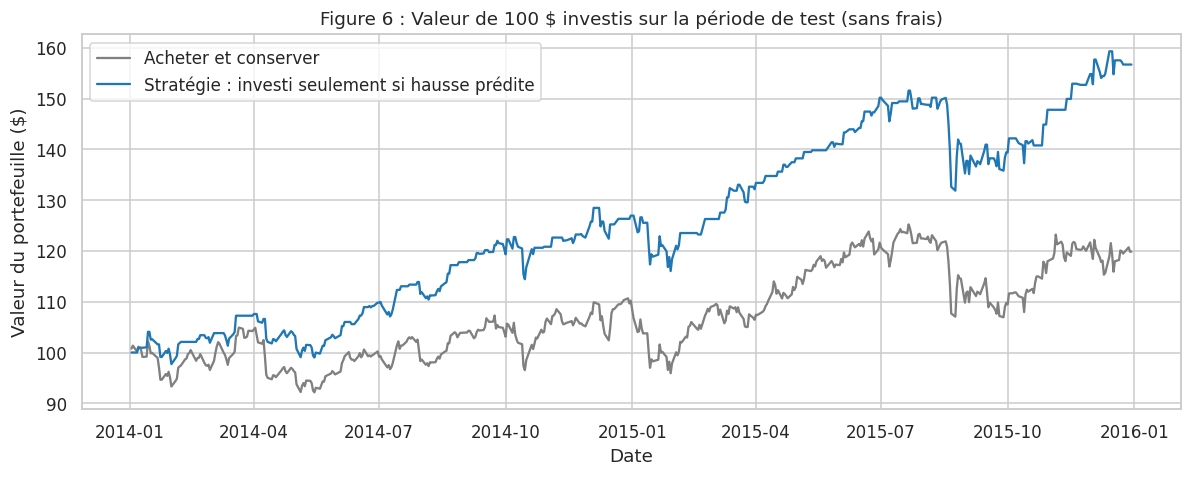

Acheter et conserver : 119.9 $
Stratégie du modèle  : 156.7 $


In [12]:
# Analyse des erreurs : coefficients et performance selon la volatilité
coefs = pd.Series(modele_final.named_steps["modele"].coef_[0], index=variables).sort_values()
print("Coefficients β de la régression logistique (variables standardisées) :")
print(coefs.round(3))

test_err = test.assign(correct=(pred_logit == y_test.values))
seuil_vol = test_err["volatilite_20j"].median()
print("\nExactitude quand la volatilité est faible :", round(test_err.loc[test_err["volatilite_20j"] <= seuil_vol, "correct"].mean(), 3))
print("Exactitude quand la volatilité est forte  :", round(test_err.loc[test_err["volatilite_20j"] > seuil_vol, "correct"].mean(), 3))
print("Part de « hausse » prédite :", round(pred_logit.mean(), 3))# Figure 6 : la stratégie du modèle rapporte-t-elle plus que « acheter et conserver » ?
rend_demain = test["rendement"].shift(-1).fillna(0) / 100
strategie = (1 + rend_demain * pred_logit).cumprod()
achat_conserv = (1 + rend_demain).cumprod()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(achat_conserv.index, achat_conserv * 100, label="Acheter et conserver", color="grey")
ax.plot(strategie.index, strategie * 100, label="Stratégie : investi seulement si hausse prédite", color="tab:blue")
ax.set_title("Figure 6 : Valeur de 100 $ investis sur la période de test (sans frais)")
ax.set_xlabel("Date")
ax.set_ylabel("Valeur du portefeuille ($)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig6_strategie.png")
plt.show()
print("Acheter et conserver :", round(achat_conserv.iloc[-1] * 100, 1), "$")
print("Stratégie du modèle  :", round(strategie.iloc[-1] * 100, 1), "$")

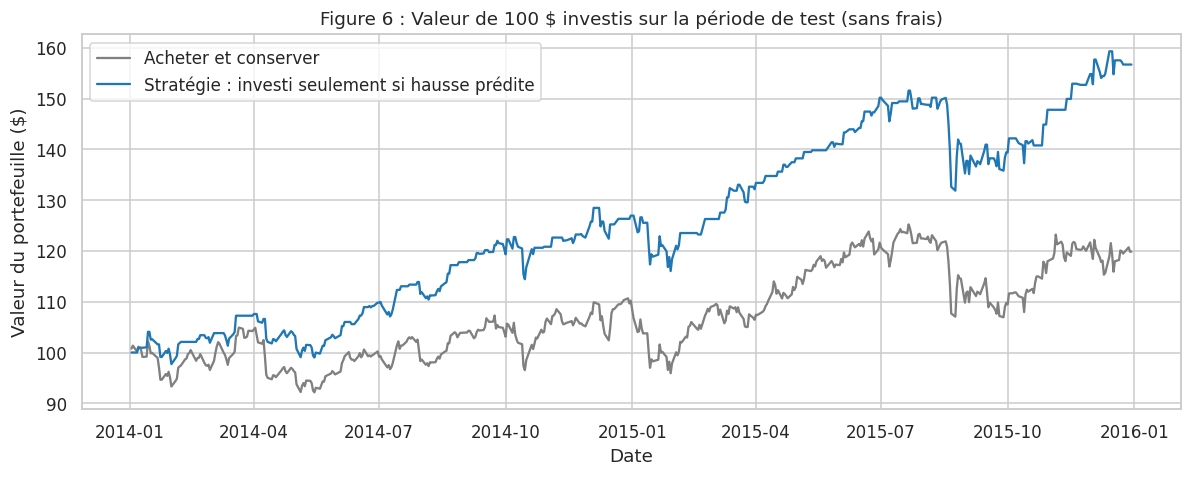

Acheter et conserver : 119.9 $
Stratégie du modèle  : 156.7 $


In [13]:
# Figure 6 : la stratégie du modèle rapporte-t-elle plus que « acheter et conserver » ?
rend_demain = test["rendement"].shift(-1).fillna(0) / 100
strategie = (1 + rend_demain * pred_logit).cumprod()
achat_conserv = (1 + rend_demain).cumprod()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(achat_conserv.index, achat_conserv * 100, label="Acheter et conserver", color="grey")
ax.plot(strategie.index, strategie * 100, label="Stratégie : investi seulement si hausse prédite", color="tab:blue")
ax.set_title("Figure 6 : Valeur de 100 $ investis sur la période de test (sans frais)")
ax.set_xlabel("Date")
ax.set_ylabel("Valeur du portefeuille ($)")
ax.legend()
plt.tight_layout()
plt.savefig("figures/fig6_strategie.png")
plt.show()
print("Acheter et conserver :", round(achat_conserv.iloc[-1] * 100, 1), "$")
print("Stratégie du modèle  :", round(strategie.iloc[-1] * 100, 1), "$")

## Résultats et conclusion

| Modèle | Exactitude test | AUC test |
|---|---|---|
| Référence : classe majoritaire | 0,471 | 0,500 |
| Référence : persistance | 0,485 | 0,462 |
| **Régression logistique** | **0,555** | 0,530 |
| Forêt aléatoire | 0,531 | 0,532 |

Sur la période de test (2014-2015), la régression logistique donne la bonne direction 55,5 % du temps. C'est mieux que les deux références naïves, qui restent sous 50 %. Le modèle ne fait pas de surapprentissage : son score est presque le même en entraînement (54,2 %) et en test.

Ce résultat reste fragile. L'AUC de 0,53 est très proche du hasard, et le modèle se trompe une fois sur deux quand le marché est agité. La stratégie basée sur le modèle transforme 100 $ en 156,7 $ (contre 119,9 $ sans modèle), mais sans compter les frais et sur une seule période.

**Limites :** une seule action, une seule période de test, pas de